<a href="https://colab.research.google.com/github/MGayathri07-code/alzheimers-disease-prediction/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# IMPORT REQUIRED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import LabelEncoder

In [3]:
# Load dataset

df = pd.read_csv("/content/drive/MyDrive/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display dataset shape
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [4]:
# Display first 5 rows

print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [5]:
# Convert the column to floats safely
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)
df['Churn'] = df['Churn'].map({'Yes': True, 'No': False})



In [6]:
# Dataset information

print(df.info())

# Statistical summary

print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
# Check missing values

print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [8]:
# Handling missing values

# Fill numerical missing values with median

num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Check again

print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
# Check duplicates

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [10]:
# IQR Method

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(f"{col} : {len(outliers)} outliers")

tenure : 0 outliers
MonthlyCharges : 0 outliers
TotalCharges : 0 outliers


In [11]:
# Removing outliers using IQR

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (7043, 21)


In [12]:
# Z-Score Method

z_scores = np.abs(stats.zscore(df[numeric_cols]))

outliers = (z_scores > 3)

print("Outliers count:")
print(outliers.sum())

Outliers count:
0


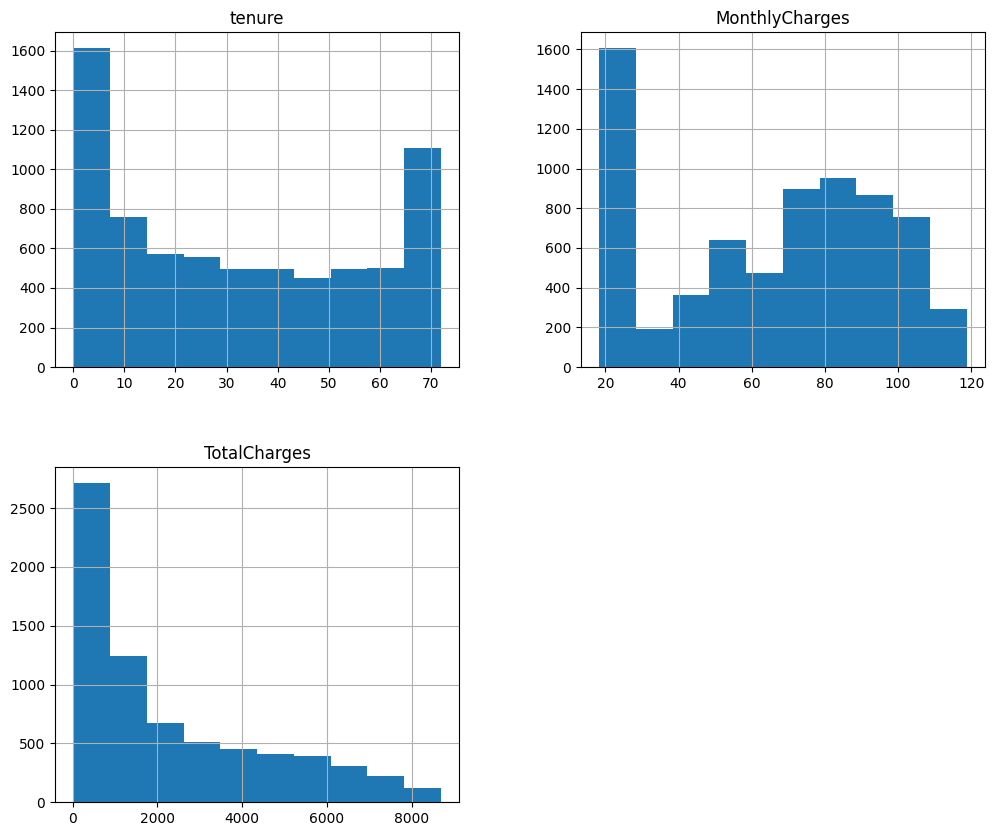

In [13]:
# Histogram

df.hist(figsize=(12,10))
plt.show()

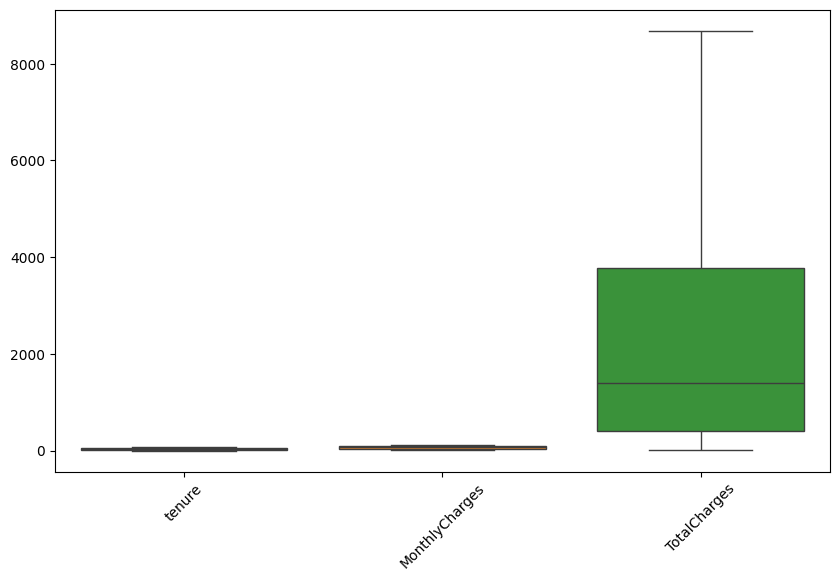

In [14]:
# Boxplot

plt.figure(figsize=(10,6))

sns.boxplot(data=df[numeric_cols])

plt.xticks(rotation=45)
plt.show()

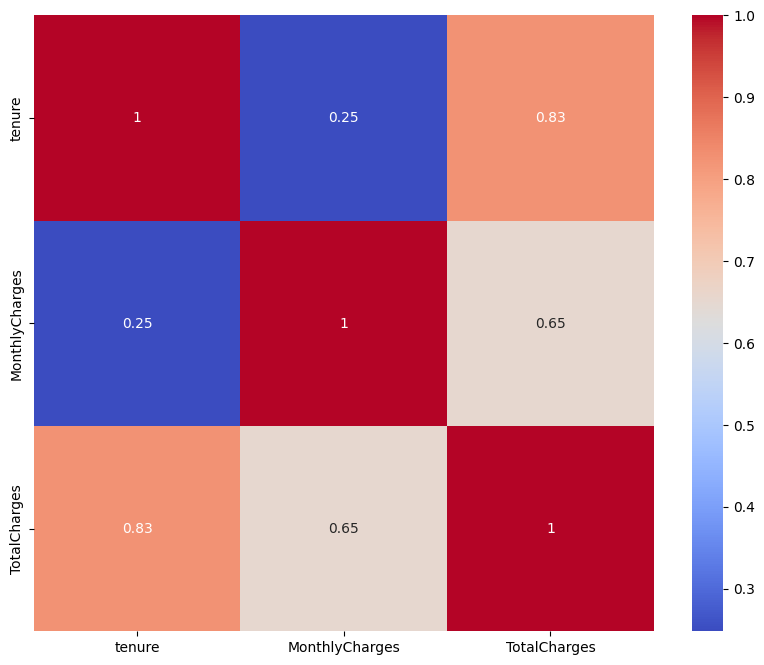

In [15]:
# Correlation Heatmap

plt.figure(figsize=(10,8))

sns.heatmap(df[numeric_cols].corr(),
            annot=True,
            cmap='coolwarm')

plt.show()

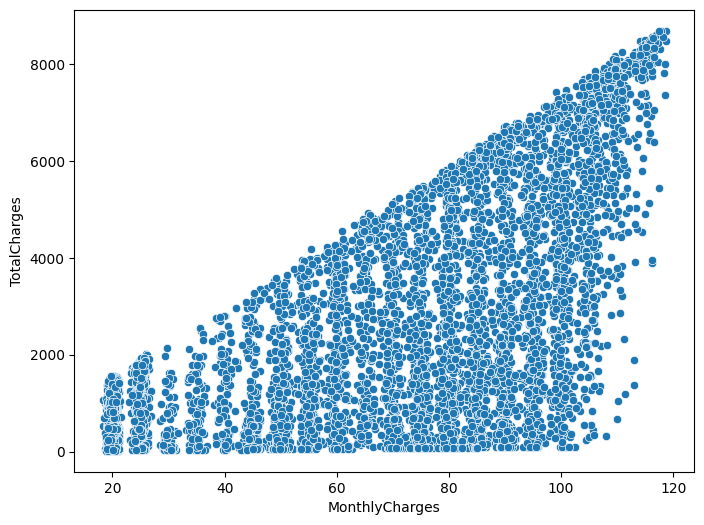

In [16]:
# Scatter plot

plt.figure(figsize=(8,6))

sns.scatterplot(x='MonthlyCharges',
                y='TotalCharges',
                data=df)

plt.show()

In [17]:
# Label Encoding

label_encoder = LabelEncoder()

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:

    df[col] = label_encoder.fit_transform(df[col])

print(df.head())

   customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0        5375       0              0        1           0       1   
1        3962       1              0        0           0      34   
2        2564       1              0        0           0       2   
3        5535       1              0        0           0      45   
4        6511       0              0        0           0       2   

   PhoneService  MultipleLines  InternetService  OnlineSecurity  ...  \
0             0              1                0               0  ...   
1             1              0                0               2  ...   
2             1              0                0               2  ...   
3             0              1                0               2  ...   
4             1              0                1               0  ...   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract  \
0                 0            0            0                0         0   


In [18]:
# Separate input and output variables

X = df.drop('Churn', axis=1)

y = df['Churn']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0        5375       0              0        1           0       1   
1        3962       1              0        0           0      34   
2        2564       1              0        0           0       2   
3        5535       1              0        0           0      45   
4        6511       0              0        0           0       2   

   PhoneService  MultipleLines  InternetService  OnlineSecurity  OnlineBackup  \
0             0              1                0               0             2   
1             1              0                0               2             0   
2             1              0                0               2             2   
3             0              1                0               2             0   
4             1              0                1               0             0   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract  \
0     

In [19]:
print(df.loc[0, 'Churn'])

False


In [53]:
from sklearn.model_selection import train_test_split

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (5634, 20)
X_test Shape: (1409, 20)
y_train Shape: (5634,)
y_test Shape: (1409,)


In [54]:
from sklearn.preprocessing import StandardScaler

# Feature Scaling

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

print(X_train)

[[-2.68964478e-01 -1.02516569e+00 -4.37749204e-01 ...  1.33926673e+00
  -4.73723375e-04 -4.21345130e-01]
 [ 3.87215293e-01 -1.02516569e+00 -4.37749204e-01 ... -1.47094882e+00
   1.07475386e+00  1.25588791e+00]
 [-4.07989794e-01  9.75452077e-01 -4.37749204e-01 ...  4.02528212e-01
  -1.37649913e+00 -1.00215117e+00]
 ...
 [ 1.08924384e+00  9.75452077e-01 -4.37749204e-01 ...  4.02528212e-01
  -1.45294499e+00 -8.77176266e-01]
 [ 8.77254881e-01  9.75452077e-01  2.28441306e+00 ...  4.02528212e-01
   1.14953785e+00 -4.81776199e-01]
 [-6.93004607e-02  9.75452077e-01 -4.37749204e-01 ... -5.34210304e-01
  -1.49781538e+00 -8.10288602e-01]]


In [55]:
from sklearn.decomposition import PCA

# Apply PCA

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train)

X_test_pca = pca.transform(X_test)

print(X_train_pca)

[[-0.61328662 -1.32512245]
 [ 2.17266254  1.72828932]
 [-2.9586311   0.25970279]
 ...
 [-1.10714651 -1.67210441]
 [-0.32739183  3.09827869]
 [-1.05072967 -1.89534042]]


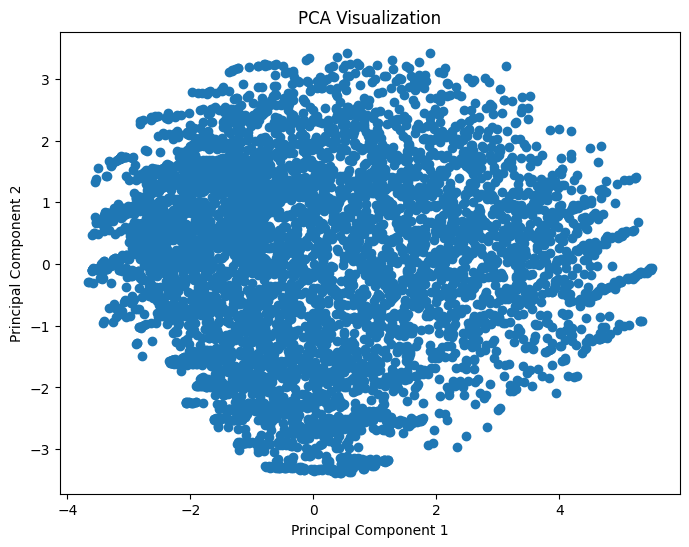

In [56]:
# PCA Visualization

plt.figure(figsize=(8,6))

plt.scatter(
    X_train_pca[:,0],
    X_train_pca[:,1]
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Visualization")

plt.show()

In [57]:
from sklearn.linear_model import LogisticRegression

# Create model

model = LogisticRegression()

In [58]:
# Train model

model.fit(X_train, y_train)

LogisticRegression()

In [59]:
# Predict values

y_pred = model.predict(X_test)

print(y_pred)

[ True False False ... False False  True]


In [60]:
# Compare actual and predicted values

results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print(results.head())

      Actual  Predicted
185     True       True
2715   False      False
3825   False      False
1807    True       True
132    False      False


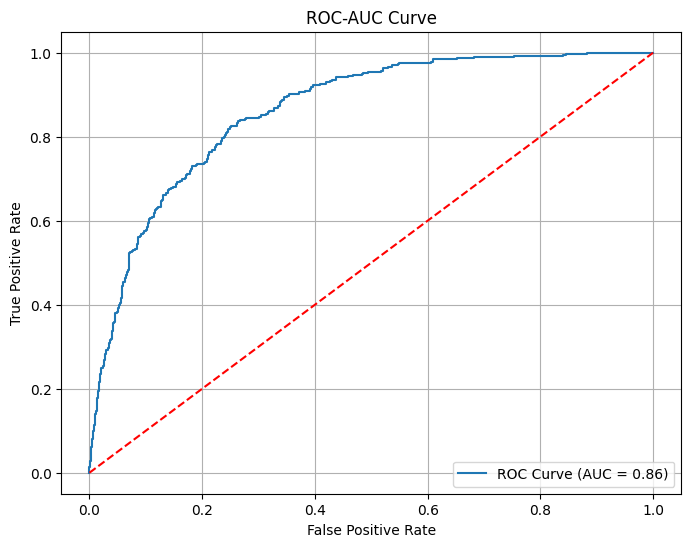

ROC-AUC Score: 0.8617802022627761


In [61]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label=True)

# Calculate AUC score
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'r--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

print("ROC-AUC Score:", roc_auc)

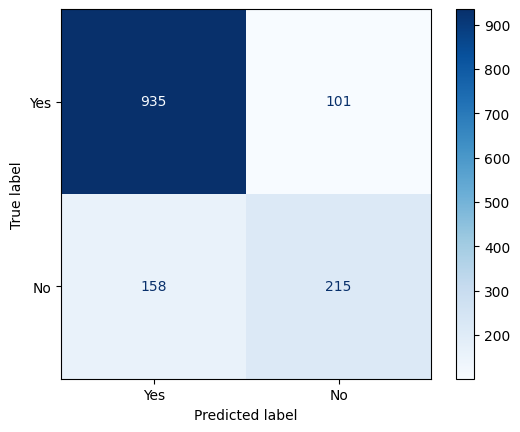

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute matrix
cm = confusion_matrix(y_test, y_pred)

# Display with customized text labels instead of just 0 and 1
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Yes', 'No'])

# Plot and render
disp.plot(cmap=plt.cm.Blues)
plt.show()


In [30]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Accuracy: Overall proportion of correct predictions
accuracy = accuracy_score(y_test, y_pred)

# 2. Precision: Out of all predicted positives, how many were actually positive?
precision = precision_score(y_test, y_pred)

# 3. Recall: Out of all actual positives, how many did we find?
recall = recall_score(y_test, y_pred)

# 4. F1-Score: Harmonic mean of precision and recall
f1 = f1_score(y_test, y_pred)

# 5. Confusion Matrix: Summary table of true vs predicted counts
matrix = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = matrix.ravel()

# Display Results
print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1-Score:  {f1:.2f}\n")
print(f"Confusion Matrix:\n{matrix}")
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")


Accuracy:  0.82
Precision: 0.68
Recall:    0.58
F1-Score:  0.62

Confusion Matrix:
[[935 101]
 [158 215]]
TN: 935, FP: 101, FN: 158, TP: 215


In [32]:
print(y_test.value_counts())
print(y_test.value_counts(normalize=True) * 100)


Churn
False    1036
True      373
Name: count, dtype: int64
Churn
False    73.527324
True     26.472676
Name: proportion, dtype: float64


In [51]:
print(model.classes_)

[False  True]
